# Project 17: Complexity Class Explorer
### An Empirical and Theoretical Exploration of P, NP, and Undecidability with Applications in Cryptography

**Course:** Theory of Computation / Design and Analysis of Algorithms  
**Team Members:** Group 17 (Team of 4 Students)  
**Tools & Technologies:** Python 3, Matplotlib, Jupyter Notebook, VS Code  

---

## 1. Project Introduction

Computational complexity theory investigates the intrinsic difficulty of computational problems and classifies them based on the resources—primarily **time** and **space**—required to solve them.

This project, **Complexity Class Explorer**, provides an interactive and rigorous bridge between theoretical computer science and empirical software development. We explore three foundational complexity tiers:
1. **P (Polynomial Time):** Problems efficiently solvable by deterministic algorithms (demonstrated via **Merge Sort**, $O(n \log n)$).
2. **NP (Nondeterministic Polynomial Time):** Problems whose proposed solutions can be efficiently verified in polynomial time, even if finding them via brute-force requires exponential time (demonstrated via **Subset Sum**, $O(n \cdot 2^n)$).
3. **Undecidability:** Problems for which no general algorithm can ever exist to decide all instances correctly (demonstrated via a **Turing Machine Simulator** and **Turing's Diagonalization Proof** of the Halting Problem).

Furthermore, we explore the real-world application of complexity theory in **Modern Cryptography**, examining why integer factorization (underpinning RSA) and password hashing (PBKDF2) rely on computational hardness to defend digital systems.


## 2. Project Objectives

The core objectives of this project are:
- **Implement and Analyze Representative Algorithms:**
  - Implement Merge Sort using the Divide-and-Conquer paradigm.
  - Implement exhaustive binary-mask Subset Sum alongside an $O(n)$ certificate verification function.
  - Construct a deterministic Turing Machine simulator and an educational diagonalization model to demonstrate the Halting Problem.
- **Provide Dual Execution Modes:**
  - **Interactive Explore Mode:** Allows users to input custom arrays, target sums, and configure Turing Machines to observe outputs and measured execution times.
  - **Automated Benchmark Mode:** Measures execution scaling across 10 increasing input sizes with safe timeout protections and generates publication-quality plots.
- **Visual Growth Comparison:**
  - Produce publication-quality Matplotlib plots illustrating the stark divergence between polynomial $O(n \log n)$ and exponential $O(n \cdot 2^n)$ growth.
- **Cryptographic Security Context:**
  - Demonstrate RSA public-key encryption and explain the computational hardness of integer factorization.
  - Demonstrate salted password hashing with configurable work factors using PBKDF2-HMAC-SHA256.
  - Clarify fundamental academic distinctions: Modern cryptographic systems rely on the assumed computational hardness of specific mathematical problems. The unresolved P versus NP question alone neither establishes nor guarantees cryptographic security.


## 3. Explanation of Computational Complexity

Computational complexity measures how the resource requirements of an algorithm grow asymptotically as the input size $n$ increases.
- **Time Complexity:** The number of elementary computational steps executed as a function of $n$.
- **Space Complexity:** The amount of working memory or tape cells required during execution.

### Big-O Notation and Asymptotic Classes:
- **$O(1)$:** Constant time (e.g., hash table lookup).
- **$O(\log n)$:** Logarithmic time (e.g., binary search).
- **$O(n)$:** Linear time (e.g., single scan through an array).
- **$O(n \log n)$:** Linearithmic time (e.g., optimal comparison-based sorting like Merge Sort).
- **$O(n^k)$:** General polynomial time (tractable problems).
- **$O(2^n)$ or $O(n \cdot 2^n)$:** Exponential time (intractable brute-force combinatorial search).
- **Non-computable / Undecidable:** Infinite step upper bound; no finite algorithm can decide all instances.


## 4. Introduction to P, NP, and Undecidable

### 4.1 Complexity Class P (Polynomial Time)
A decision problem belongs to **P** if there exists a deterministic Turing Machine that solves every instance of input length $n$ in time $O(n^k)$ for some constant $k \ge 0$. Problems in P are considered computationally **tractable** or efficiently solvable. Examples include sorting, shortest path algorithms (Dijkstra), and primality testing (AKS algorithm).

### 4.2 Complexity Class NP (Nondeterministic Polynomial Time)
A decision problem belongs to **NP** if any "YES" instance possesses a certificate (proof or witness) that can be verified by a deterministic Turing Machine in polynomial time $O(n^k)$. Alternatively, NP is the class of problems decidable in polynomial time by a *Nondeterministic Turing Machine*.
- **NP-Hard:** A problem is NP-hard if every problem in NP can be polynomial-time reduced (Karp reduction) to it.
- **NP-Complete:** A problem that is both in NP and NP-Hard (e.g., 3-SAT, Subset Sum, Traveling Salesperson decision variant).

### 4.3 The P vs NP Millennium Problem
The open question $P \stackrel{?}{=} NP$ asks whether every problem whose solutions can be verified in polynomial time can also be solved in polynomial time. Formulated by Stephen Cook (1971), it is one of the seven Clay Mathematics Institute Millennium Prize Problems. The overwhelming scientific consensus is $P \neq NP$, but it remains mathematically unproven.

### 4.4 Undecidability and the Halting Problem
Introduced by Alan Turing in 1936, a problem is **undecidable** if no Turing Machine can be constructed that halts on all inputs and correctly returns a binary decision. The Halting Problem asks whether an arbitrary computer program $P$ will halt when run on input $I$. Turing proved that the Halting Problem is undecidable using a proof technique known as **diagonalization**.


## 5. Merge Sort Implementation Demonstration (P Class)

Merge Sort is a canonical example of an algorithm in complexity class **P**. It operates under the **Divide-and-Conquer** paradigm:
1. **Divide:** Split the input array of size $n$ into two halves of size $\lfloor n/2 \rfloor$ and $\lceil n/2 \rceil$.
2. **Conquer:** Recursively sort both sub-arrays using Merge Sort.
3. **Combine:** Merge the two sorted sub-arrays into a single sorted array in linear time $O(n)$.

### Mathematical Recurrence:
$$T(n) = 2T\left(\frac{n}{2}\right) + \Theta(n), \quad T(1) = \Theta(1)$$

By the **Master Theorem** ($a = 2, b = 2, f(n) = \Theta(n^1)$, where $\log_b a = \log_2 2 = 1$):
$$T(n) = \Theta(n^{\log_2 2} \log n) = \Theta(n \log n)$$

- **Best, Average, and Worst-Case:** $\Theta(n \log n)$ across all cases because recursive partitioning and merging occur identically regardless of initial element ordering.
- **Auxiliary Space Complexity:** $O(n)$ due to temporary arrays allocated during merging, plus $O(\log n)$ call stack frames.


In [1]:
# 5.1 Import and execute Merge Sort from the codebase
from src.merge_sort import merge_sort

test_cases = {
    "Random Integers": [38, 27, 43, 3, 9, 82, 10],
    "Already Sorted": [1, 2, 3, 4, 5, 6],
    "Reverse Sorted": [9, 8, 7, 6, 5, 4],
    "Duplicates": [5, 2, 8, 5, 2, 8, 1],
    "Negative Values": [-10, 5, -3, 0, 15, -7],
    "Single Element": [42],
    "Empty List": [],
}

print(f"{'Input Type':<18} | {'Original Array':<32} | {'Sorted Result'}")
print("-" * 80)
for label, data in test_cases.items():
    sorted_data = merge_sort(data)
    print(f"{label:<18} | {str(data):<32} | {sorted_data}")


Input Type         | Original Array                   | Sorted Result
--------------------------------------------------------------------------------
Random Integers    | [38, 27, 43, 3, 9, 82, 10]       | [3, 9, 10, 27, 38, 43, 82]
Already Sorted     | [1, 2, 3, 4, 5, 6]               | [1, 2, 3, 4, 5, 6]
Reverse Sorted     | [9, 8, 7, 6, 5, 4]               | [4, 5, 6, 7, 8, 9]
Duplicates         | [5, 2, 8, 5, 2, 8, 1]            | [1, 2, 2, 5, 5, 8, 8]
Negative Values    | [-10, 5, -3, 0, 15, -7]          | [-10, -7, -3, 0, 5, 15]
Single Element     | [42]                             | [42]
Empty List         | []                               | []


## 6. Interactive Merge Sort Example

Below is a reproducible demonstration of the Interactive Explore Mode for Merge Sort using a predefined sample array (`[45, 12, 89, 3, 21, 7, 64, 50, 18]`).

> **Note on Interactivity:** This notebook cell demonstrates the explore workflow using fixed sample inputs to ensure automated, reproducible execution. To interactively enter your own arbitrary input arrays and experiment with custom inputs, run the primary terminal application via `python main.py` (Option 1).


In [2]:
# 6.1 Interactive-style Merge Sort execution with timing
from time import perf_counter
from src.merge_sort import merge_sort

user_array = [45, 12, 89, 3, 21, 7, 64, 50, 18]

print("========== MERGE SORT – P CLASS ==========\n")
print("Input Array:   ", user_array)

t0 = perf_counter()
sorted_array = merge_sort(user_array)
elapsed_ms = (perf_counter() - t0) * 1000

print("Sorted Array:  ", sorted_array)
print(f"Execution Time: {elapsed_ms:.4f} ms")
print("\nTime Complexity:  O(n log n)")
print("Space Complexity: O(n)")
print("\nExplanation:")
print("Merge Sort repeatedly divides the array into smaller")
print("subarrays, sorts them, and merges them.")
print("\nClassification: P (Polynomial Time)")


========== MERGE SORT – P CLASS ==========

Input Array:    [45, 12, 89, 3, 21, 7, 64, 50, 18]
Sorted Array:   [3, 7, 12, 18, 21, 45, 50, 64, 89]
Execution Time: 0.0211 ms

Time Complexity:  O(n log n)
Space Complexity: O(n)

Explanation:
Merge Sort repeatedly divides the array into smaller
subarrays, sorts them, and merges them.

Classification: P (Polynomial Time)


## 7. Subset Sum Implementation Demonstration (NP Class)

The **Subset Sum** problem asks: given a multiset of integers $S$ and an integer target $T$, does there exist a subset $S' \subseteq S$ such that:
$$\sum_{x \in S'} x = T$$

### Why is Subset Sum in NP?
1. **Exhaustive Brute-Force Solving:**  
   Every element can either be included or excluded from a candidate subset. For a set of size $n$, there are $2^n$ possible subsets. Using binary bitmask enumeration, generating and summing each candidate subset takes up to $n$ operations, yielding worst-case time complexity:
   $$O(n \cdot 2^n)$$
   As $n$ grows, this exponential growth quickly becomes intractable for classical computers.
2. **Polynomial-Time Verification:**  
   If an oracle or user provides a proposed subset certificate $S'$, verifying whether $\sum_{x \in S'} x = T$ and confirming that all elements belong to $S$ requires only linear time $O(n)$. This **asymmetry** between hard solving and easy verification is the hallmark of **NP**.


In [3]:
# 7.1 Import Subset Sum solver and polynomial-time verifier
from src.subset_sum import subset_sum_bruteforce, verify_subset_sum

numbers = [12, 7, 19, 4, 25, 8]
target_yes = 31      # 12 + 19 = 31
target_no = 999      # Impossible target

print("Problem Instance:", numbers)
print(f"Target {target_yes} exists? ->", subset_sum_bruteforce(numbers, target_yes))
print(f"Target {target_no} exists? ->", subset_sum_bruteforce(numbers, target_no))

# Polynomial-time verification demonstration
candidate_certificate = [12, 19]
is_valid = verify_subset_sum(numbers, candidate_certificate, target_yes)
print(f"\nVerification of certificate {candidate_certificate} for target {target_yes}:")
print(f"Verified in O(n) time? -> {is_valid}")


Problem Instance: [12, 7, 19, 4, 25, 8]
Target 31 exists? -> True
Target 999 exists? -> False

Verification of certificate [12, 19] for target 31:
Verified in O(n) time? -> True


## 8. Interactive Subset Sum Example

Below is a reproducible demonstration of the Interactive Explore Mode for Subset Sum using a fixed sample instance (`[2, 3, 7, 8, 10]` with target `11`).

> **Note on Interactivity:** This notebook cell demonstrates the explore workflow and certificate verification using fixed sample values to ensure reproducible execution. To interactively supply custom candidate numbers and arbitrary target sums, run the primary terminal application via `python main.py` (Option 2).


In [4]:
# 8.1 Interactive-style Subset Sum execution with solution retrieval
from time import perf_counter
from src.subset_sum import find_subset_sum_bruteforce, verify_subset_sum

user_numbers = [2, 3, 7, 8, 10]
target_sum = 11

print("========== SUBSET SUM – NP CLASS ==========\n")
print(f"Array Elements: {user_numbers}")
print(f"Target Sum:     {target_sum}")
print("\nSearching for a subset...")

t0 = perf_counter()
subset, timed_out = find_subset_sum_bruteforce(user_numbers, target_sum, timeout_seconds=5.0)
elapsed_ms = (perf_counter() - t0) * 1000

if subset is not None:
    print(f"\nSubset Found:   {subset}")
    print(f"Subset Sum:     {sum(subset)}")
    print(f"Execution Time: {elapsed_ms:.4f} ms")
    
    # Polynomial verification
    verified = verify_subset_sum(user_numbers, subset, target_sum)
    print(f"O(n) Certificate Verification: {verified}")
else:
    print(f"\nNo subset found summing to {target_sum}.")

print("\nTime Complexity:  O(n * 2^n) for current brute-force implementation.")
print("Verification:     O(n) linear polynomial time.")
print("\nExplanation:")
print("The algorithm explores possible subsets to determine")
print("whether any subset has the required target sum.")
print("\nClassification:")
print("Subset Sum Decision Problem – NP-Complete")


========== SUBSET SUM – NP CLASS ==========

Array Elements: [2, 3, 7, 8, 10]
Target Sum:     11

Searching for a subset...

Subset Found:   [3, 8]
Subset Sum:     11
Execution Time: 0.0150 ms
O(n) Certificate Verification: True

Time Complexity:  O(n * 2^n) for current brute-force implementation.
Verification:     O(n) linear polynomial time.

Explanation:
The algorithm explores possible subsets to determine
whether any subset has the required target sum.

Classification:
Subset Sum Decision Problem – NP-Complete


## 9. Turing Machine Simulator Demonstration (Undecidable)

### 9.1 Simulating State Machines and Step Bounds
A deterministic Turing Machine consists of an infinite tape, a tape head, discrete states, and transition rules $\delta(q, \sigma) \to (q', \sigma', D)$.

We demonstrate three distinct operational outcomes:
1. **HALTED:** Machine reaches a designated halting state (`q_halt`).
2. **CYCLE DETECTED:** Machine enters a repeating periodic configuration $(q, \text{head}, \text{tape})$ from which it can never escape.
3. **UNKNOWN (STEP LIMIT REACHED):** Machine hits its configured step bound without halting.
   > **Critical Academic Rule:** Never report `Halts? False` when a step bound is reached. The status is strictly **UNKNOWN**, as finite simulation cannot distinguish slow termination from an infinite loop.


In [5]:
# 9.1 Execute Turing Machine configurations
from src.halting.turing_machine import (
    create_halting_machine,
    create_infinite_loop_machine,
    create_busy_beaver_or_counter_machine,
)

print("=" * 70)
print(" 1. MACHINE THAT HALTS (Binary Bit Inverter)")
print("=" * 70)
tm1 = create_halting_machine("1101")
res1 = tm1.run(max_steps=50)
print(f"Result Category: {res1.result_category}")
print(f"Steps Executed:  {res1.steps}")
print(f"Tape View:       {res1.tape_content}")
print(f"Explanation:     {res1.explanation}\n")

print("=" * 70)
print(" 2. MACHINE IN PERIODIC CYCLE (Ping-Pong State Loop)")
print("=" * 70)
tm2 = create_infinite_loop_machine()
res2 = tm2.run(max_steps=50, detect_cycles=True)
print(f"Result Category: {res2.result_category}")
print(f"Steps Executed:  {res2.steps}")
print(f"Explanation:     {res2.explanation}\n")

print("=" * 70)
print(" 3. MACHINE REACHING STEP LIMIT (Unknown Status)")
print("=" * 70)
tm3 = create_busy_beaver_or_counter_machine()
res3 = tm3.run(max_steps=20)
print(f"Result Category: {res3.result_category}")
print(f"Steps Executed:  {res3.steps}")
print(f"Explanation:     {res3.explanation}")


 1. MACHINE THAT HALTS (Binary Bit Inverter)
Result Category: HALTED
Steps Executed:  5
Tape View:       BB0010BBB
Explanation:     Machine reached halting state 'q_halt' after 5 step(s).

 2. MACHINE IN PERIODIC CYCLE (Ping-Pong State Loop)
Result Category: CYCLE DETECTED
Steps Executed:  4
Explanation:     Periodic repeating configuration detected at step 4. The machine will repeat this cycle indefinitely without halting.

 3. MACHINE REACHING STEP LIMIT (Unknown Status)
Result Category: UNKNOWN (STEP LIMIT REACHED)
Steps Executed:  20
Explanation:     Simulation step limit (20) was reached while in state 'q0'. The halting status is UNKNOWN: finite simulation alone cannot determine whether the machine would halt on a subsequent step or loop forever.


## 10. Halting Problem and Turing's Diagonalization Proof

### 10.1 The Contradiction Behind the Halting Problem
Alan Turing proved that no general decider $H(P, I)$ can exist that accurately predicts whether every arbitrary program $P$ halts on input $I$.

1. Assume a general decider $H(P, I)$ exists:
   $$H(P, I) = \begin{cases} \text{HALTS} & \text{if } P(I) \text{ halts} \\ \text{LOOPS\_FOREVER} & \text{if } P(I) \text{ does not halt} \end{cases}$$
2. Construct an adversary program $D(P)$ that calls $H(P, P)$:
   - If $H(P, P)$ predicts $\text{HALTS}$, $D$ enters an infinite loop.
   - If $H(P, P)$ predicts $\text{LOOPS\_FOREVER}$, $D$ halts immediately.
3. Now evaluate $D(D)$ (running $D$ on its own source code):
   - If $H(D, D) = \text{HALTS} \implies D(D)$ loops forever. **Contradiction!**
   - If $H(D, D) = \text{LOOPS\_FOREVER} \implies D(D)$ halts. **Contradiction!**
4. Conclusion: Decider $H$ cannot exist. The Halting Problem is **undecidable**.

> **Academic Note on Diagonalization:** This demonstration is an educational representation of the logical contradiction and does not implement a real universal Halting Problem decider.


In [6]:
# 10.1 Educational Diagonalization Paradox Demonstration
from src.halting.diagonalization import demonstrate_diagonalization_paradox

paradox = demonstrate_diagonalization_paradox()

print("=" * 75)
print(" EDUCATIONAL DIAGONALIZATION PROOF DEMONSTRATION")
print("=" * 75)
print("\n[Hypothesis A: Assume H(D, D) predicts 'HALTS']")
print("  Premise:       ", paradox["hypothesis_halts"]["assumption"])
print("  Action of D(D):", paradox["hypothesis_halts"]["d_behavior"])
print("  Result:        ", paradox["hypothesis_halts"]["contradiction"])

print("\n[Hypothesis B: Assume H(D, D) predicts 'LOOPS_FOREVER']")
print("  Premise:       ", paradox["hypothesis_loops"]["assumption"])
print("  Action of D(D):", paradox["hypothesis_loops"]["d_behavior"])
print("  Result:        ", paradox["hypothesis_loops"]["contradiction"])

print("\n[Mathematical Conclusion]")
print(" ", paradox["mathematical_conclusion"])


 EDUCATIONAL DIAGONALIZATION PROOF DEMONSTRATION

[Hypothesis A: Assume H(D, D) predicts 'HALTS']
  Premise:        Suppose H(D, D) returns 'HALTS'.
  Action of D(D): By definition, D reads 'HALTS' and enters an infinite loop.
  Result:         Contradiction: H claimed D(D) halts, but D(D) runs forever! Therefore H failed.

[Hypothesis B: Assume H(D, D) predicts 'LOOPS_FOREVER']
  Premise:        Suppose H(D, D) returns 'LOOPS_FOREVER'.
  Action of D(D): By definition, D reads 'LOOPS_FOREVER' and terminates immediately.
  Result:         Contradiction: H claimed D(D) loops forever, but D(D) halted! Therefore H failed.

[Mathematical Conclusion]
  In both logically possible cases, H is proven wrong about D(D). Because H was defined as a general decider that is always correct on any input, the initial premise that such an algorithm H can exist must be false. Hence, the Halting Problem is UNDECIDABLE.


## 11. Cryptography Application: RSA Public-Key Cryptography

RSA (Rivest, Shamir, Adleman, 1978) relies on the asymmetry between multiplication and integer factorization:
1. Primes $p$ and $q$ are chosen.
2. Modulus $n = p \cdot q$ and totient $\phi(n) = (p-1)(q-1)$.
3. Public exponent $e$ coprime to $\phi(n)$; private exponent $d = e^{-1} \pmod{\phi(n)}$.
4. **Encryption & Decryption Efficiency:** RSA encryption ($c = m^e \pmod n$) and decryption ($m = c^d \pmod n$) use modular exponentiation, which requires a polynomial number of bit operations in the size of the modulus under standard arithmetic models.

### Complexity Analysis of Integer Factorization:
- Classical factoring algorithms (e.g. General Number Field Sieve, GNFS) run in sub-exponential time:
  $$O\left(\exp\left(c \cdot (\log n)^{1/3} (\log \log n)^{2/3}\right)\right)$$
- In its decision formulation (determining whether $n$ has a prime factor $\le k$), integer factorization belongs to both $NP$ and $\text{co-}NP$. It is widely suspected to be NP-intermediate rather than NP-complete.
- Modern cryptographic systems rely on the assumed computational hardness of specific mathematical problems. The unresolved P versus NP question alone neither establishes nor guarantees cryptographic security.


In [7]:
# 11.1 Educational RSA Demonstration
from RSAdemo import generate_keys, encrypt, decrypt

p, q = 61, 53
pub_key, priv_key, phi = generate_keys(p, q)
e, n = pub_key
d, _ = priv_key

message = 42
ciphertext = encrypt(message, pub_key)
recovered = decrypt(ciphertext, priv_key)

print("=" * 60)
print(" RSA EDUCATIONAL DEMONSTRATION")
print("=" * 60)
print(f"Selected Primes:        p = {p}, q = {q}")
print(f"Public Modulus:         n = p * q = {n}")
print(f"Euler's Totient:        phi(n) = (p-1)*(q-1) = {phi}")
print(f"Public Key (e, n):      ({e}, {n})")
print(f"Private Key (d, n):     ({d}, {n})")
print(f"Original Message:       {message}")
print(f"Encrypted Ciphertext:   {ciphertext}")
print(f"Decrypted Message:      {recovered}")
print(f"Decryption Successful?  {message == recovered}")


 RSA EDUCATIONAL DEMONSTRATION
Selected Primes:        p = 61, q = 53
Public Modulus:         n = p * q = 3233
Euler's Totient:        phi(n) = (p-1)*(q-1) = 3120
Public Key (e, n):      (7, 3233)
Private Key (d, n):     (1783, 3233)
Original Message:       42
Encrypted Ciphertext:   240
Decrypted Message:      42
Decryption Successful?  True


## 12. Cryptography Application: Salted Password Hashing

### Why Passwords Cannot Be Encrypted or Plainly Hashed:
- **Encryption is Reversible:** Storing encrypted passwords exposes them if the decryption key is compromised.
- **Fast Hashes (MD5, SHA-256) are Unsafe:** GPUs can calculate billions of raw SHA-256 hashes per second.

### Security Mechanisms:
1. **Cryptographic Salt:** A unique random string (via OS CSPRNG `secrets.token_bytes`) added to each password before hashing, defeating rainbow table attacks.
2. **Work Factor (Iteration Tuning):** PBKDF2-HMAC-SHA256 applies thousands of recursive iterations, forcing attackers to spend substantial CPU cycles per guess.


In [8]:
# 12.1 Password Hashing Demonstration
from src.password_hashing import (
    demonstrate_password_hashing,
    benchmark_work_factors,
)

demo = demonstrate_password_hashing()

print("=" * 65)
print(" SECURE PASSWORD HASHING DEMONSTRATION")
print("=" * 65)
print(f"Algorithm:             {demo['algorithm']}")
print(f"Work Factor (Iters):   {demo['iterations']:,}")
print(f"Random Salt (Hex):     {demo['salt_hex']}")
print(f"Derived Key (Hex):     {demo['hash_hex'][:32]}... (truncated)")
print(f"Correct Password Match:{demo['valid_verification']}")
print(f"Wrong Password Match:  {demo['invalid_verification']}")

# Benchmark work factors
print("\n" + "=" * 65)
print(" WORK FACTOR SCALING BENCHMARK")
print("=" * 65)
wf_results = benchmark_work_factors(iteration_counts=(10_000, 50_000, 100_000, 200_000))
for wf in wf_results:
    print(f"Iterations: {wf['iterations']:<8,} | Hashing Time: {wf['time_ms']:.2f} ms")


 SECURE PASSWORD HASHING DEMONSTRATION
Algorithm:             pbkdf2_hmac_sha256
Work Factor (Iters):   100,000
Random Salt (Hex):     3cb1b67974cf4cb5e6e143319588ea5c
Derived Key (Hex):     d8928acf50c57d50d24301325fa483b3... (truncated)
Correct Password Match:True
Wrong Password Match:  False

 WORK FACTOR SCALING BENCHMARK
Iterations: 10,000   | Hashing Time: 2.46 ms
Iterations: 50,000   | Hashing Time: 17.54 ms
Iterations: 100,000  | Hashing Time: 25.34 ms
Iterations: 200,000  | Hashing Time: 52.34 ms


## 13. Runtime Benchmarking Mode

We execute systematic benchmarks across 10 increasing input sizes:
- **Merge Sort Sizes:** `[10, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000]`
- **Subset Sum Sizes:** `[5, 8, 10, 12, 15, 18, 20, 22, 24, 26]`
- **Safe Timeout Guard:** A 2.0-second safety threshold halts execution before large combinatorial sizes freeze the notebook.


In [9]:
# 13.1 Execute benchmarks across 10 input sizes
from src.merge_sort import benchmark_merge_sort, DEFAULT_MERGE_SORT_SIZES
from src.subset_sum import benchmark_subset_sum, DEFAULT_SUBSET_SUM_SIZES

print("Benchmarking Merge Sort (P)...")
merge_data = benchmark_merge_sort(sizes=DEFAULT_MERGE_SORT_SIZES, trials=3, seed=42)

print("Benchmarking Subset Sum (NP-Complete)...")
subset_data = benchmark_subset_sum(sizes=DEFAULT_SUBSET_SUM_SIZES, trials=1, seed=42, timeout_seconds=2.0)

# Display tabular results
print(f"\n{'=' * 30} MERGE SORT RESULTS {'=' * 30}")
print(f"{'Input Size (n)':<16} | {'Runtime (ms)':<18} | {'Complexity Model'}")
print("-" * 65)
for r in merge_data:
    print(f"{r['n']:<16} | {r['runtime_ms']:<18.4f} | O(n log n)")

print(f"\n{'=' * 30} SUBSET SUM RESULTS {'=' * 30}")
print(f"{'Input Size (n)':<16} | {'Runtime (ms)':<18} | {'Subsets Explored (2^n)'}")
print("-" * 65)
for r in subset_data:
    time_str = f"{r['runtime_ms']:.4f} ms" if r["runtime_ms"] is not None else "Timed Out (> 2.0s)"
    subsets_explored = f"{2**r['n']:,}" if r["runtime_ms"] is not None else f"~{2**r['n']:,} (Skipped)"
    print(f"{r['n']:<16} | {time_str:<18} | {subsets_explored}")


Benchmarking Merge Sort (P)...
Benchmarking Subset Sum (NP-Complete)...

============================== MERGE SORT RESULTS ==============================
Input Size (n)   | Runtime (ms)       | Complexity Model
-----------------------------------------------------------------
10               | 0.0191             | O(n log n)
50               | 0.1156             | O(n log n)
100              | 0.2554             | O(n log n)
200              | 0.5393             | O(n log n)
500              | 2.5312             | O(n log n)
1000             | 3.6970             | O(n log n)
2000             | 8.0539             | O(n log n)
5000             | 32.8764            | O(n log n)
10000            | 44.0364            | O(n log n)
20000            | 86.4893            | O(n log n)

============================== SUBSET SUM RESULTS ==============================
Input Size (n)   | Runtime (ms)       | Subsets Explored (2^n)
-----------------------------------------------------------------
5 

## 14. Matplotlib Visualizations

Visualizing measured runtimes reveals the empirical divergence between polynomial and exponential growth:
1. **Merge Sort:** Smooth linearithmic scaling ($O(n \log n)$).
2. **Subset Sum:** Explosive exponential scaling ($O(n \cdot 2^n)$).
3. **Combined Plot (Logarithmic Scale):** Both curves plotted on a logarithmic y-axis.


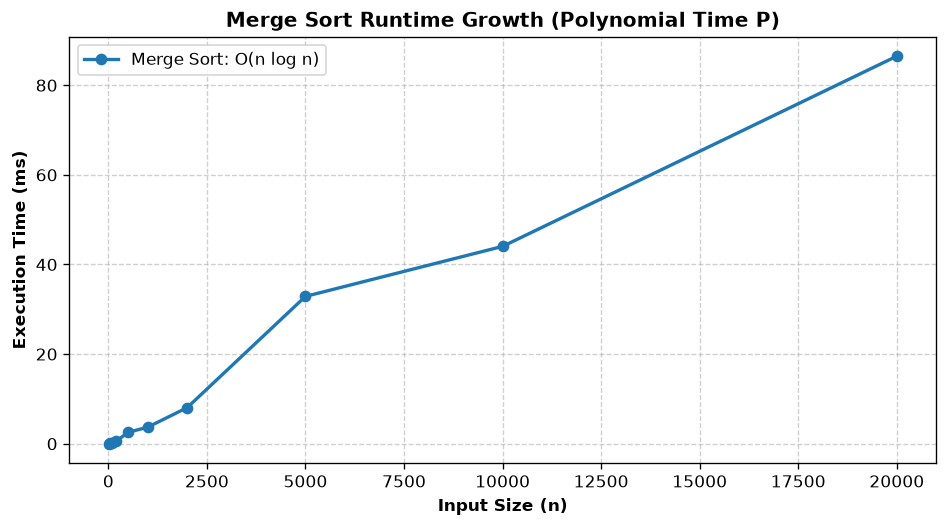

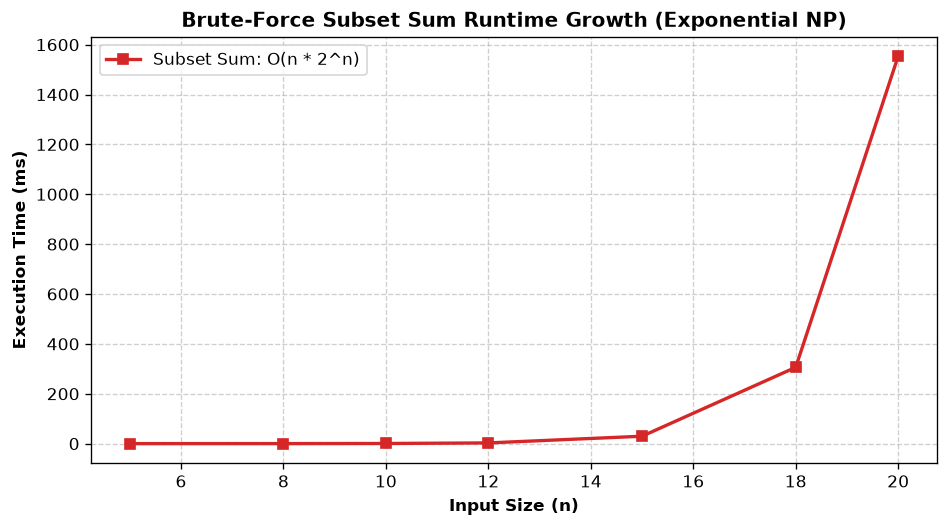

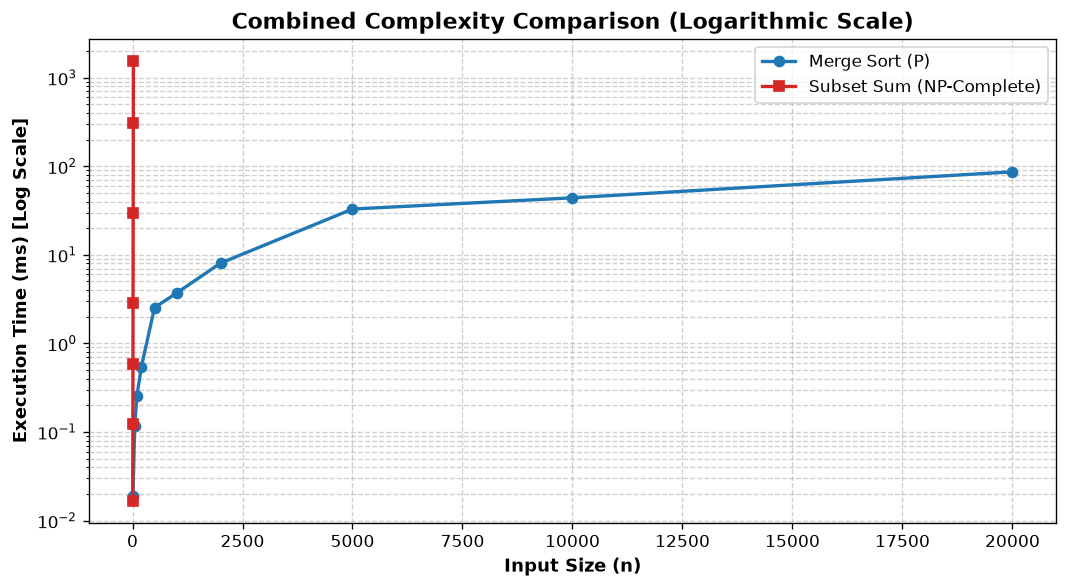

In [10]:
# 14.1 Matplotlib Runtime Visualizations
import matplotlib.pyplot as plt

# 1. Merge Sort Plot
fig, ax = plt.subplots(figsize=(8, 4.5))
ns_merge = [r["n"] for r in merge_data]
times_merge = [r["runtime_ms"] for r in merge_data]
ax.plot(ns_merge, times_merge, marker='o', color='#1f77b4', linewidth=2, label="Merge Sort: O(n log n)")
ax.set_title("Merge Sort Runtime Growth (Polynomial Time P)", fontsize=12, fontweight='bold')
ax.set_xlabel("Input Size (n)", fontsize=10, fontweight='bold')
ax.set_ylabel("Execution Time (ms)", fontsize=10, fontweight='bold')
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

# 2. Subset Sum Plot
fig, ax = plt.subplots(figsize=(8, 4.5))
valid_subset = [r for r in subset_data if r["runtime_ms"] is not None]
ns_subset = [r["n"] for r in valid_subset]
times_subset = [r["runtime_ms"] for r in valid_subset]
ax.plot(ns_subset, times_subset, marker='s', color='#d62728', linewidth=2, label="Subset Sum: O(n * 2^n)")
ax.set_title("Brute-Force Subset Sum Runtime Growth (Exponential NP)", fontsize=12, fontweight='bold')
ax.set_xlabel("Input Size (n)", fontsize=10, fontweight='bold')
ax.set_ylabel("Execution Time (ms)", fontsize=10, fontweight='bold')
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

# 3. Combined Comparison Plot (Logarithmic Scale)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ns_merge, times_merge, marker='o', color='#1f77b4', linewidth=2, label="Merge Sort (P)")
ax.plot(ns_subset, times_subset, marker='s', color='#d62728', linewidth=2, label="Subset Sum (NP-Complete)")
ax.set_yscale('log')
ax.set_title("Combined Complexity Comparison (Logarithmic Scale)", fontsize=13, fontweight='bold')
ax.set_xlabel("Input Size (n)", fontsize=11, fontweight='bold')
ax.set_ylabel("Execution Time (ms) [Log Scale]", fontsize=11, fontweight='bold')
ax.grid(True, which="both", linestyle="--", alpha=0.6)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()


## 15. Comparison of the Three Concepts

| Complexity Class | Representative Demonstration | Time Complexity | Verification Complexity | Halting/Decidability Guarantee |
| :--- | :--- | :--- | :--- | :--- |
| **P (Polynomial Time)** | Merge Sort | $\Theta(n \log n)$ | $O(n)$ | Decidable (Guaranteed to halt in polynomial time) |
| **NP (Nondeterministic Poly)** | Subset Sum (Decision) | Brute-force $O(n \cdot 2^n)$ | $O(n)$ Linear Time | Decidable (Halts in exponential time) |
| **Undecidable** | Halting Problem | No general algorithm exists | Unverifiable in general | **Undecidable** (No general decider can exist) |

### Key Theoretical Distinctions:
1. **Decision vs Sorting:** P and NP formally describe classes of decision problems with binary YES/NO outputs. Merge Sort is a polynomial-time sorting algorithm representing tractability in P.
2. **Asymmetry in NP:** Subset Sum is NP-Complete. While solving takes exponential time via brute-force, a proposed certificate is verified in linear $O(n)$ time.
3. **Undecidability vs Step Limit:** Reaching a step limit in a Turing Machine simulation results in **UNKNOWN**, not proof of non-termination.
4. **P vs NP Status:** Whether $P = NP$ remains an open problem.
5. **Cryptography Complexity:** Modern cryptographic systems rely on the assumed computational hardness of specific mathematical problems. The unresolved P versus NP question alone neither establishes nor guarantees cryptographic security. In particular, integer factorization in its decision formulation is in $NP \cap \text{co-}NP$ (suspected NP-intermediate, not NP-complete).


## 16. Conclusion

Through **Project 17: Complexity Class Explorer**, we demonstrated the computational continuum:
- From **tractable polynomial-time algorithms** ($P$) like Merge Sort that scale gracefully to large datasets,
- To **intractable search problems** ($NP$) like Subset Sum whose solutions can be verified easily but are exponentially expensive to find by brute force,
- To **provably unsolvable problems** (Undecidable) like the Halting Problem that defy any algorithmic resolution.

In cryptography, we highlighted how modern security leverages the computational asymmetry between easy legitimate operations and hard adversarial inversions. This establishes a profound link between theoretical computational complexity and the security of real-world digital infrastructure.
